=== MODEL COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.9053,0.8535,0.8295,0.8413,0.9671
1,Random Forest,0.8749,0.8444,0.7191,0.7767,0.9493
2,Logistic Regression,0.8690,0.7990,0.7578,0.7778,0.9394



=== BEST MODEL: Gradient Boosting ===
              precision    recall  f1-score   support

           0       0.93      0.94      0.93      6974
           1       0.85      0.83      0.84      3026

    accuracy                           0.91     10000
   macro avg       0.89      0.88      0.89     10000
weighted avg       0.90      0.91      0.90     10000



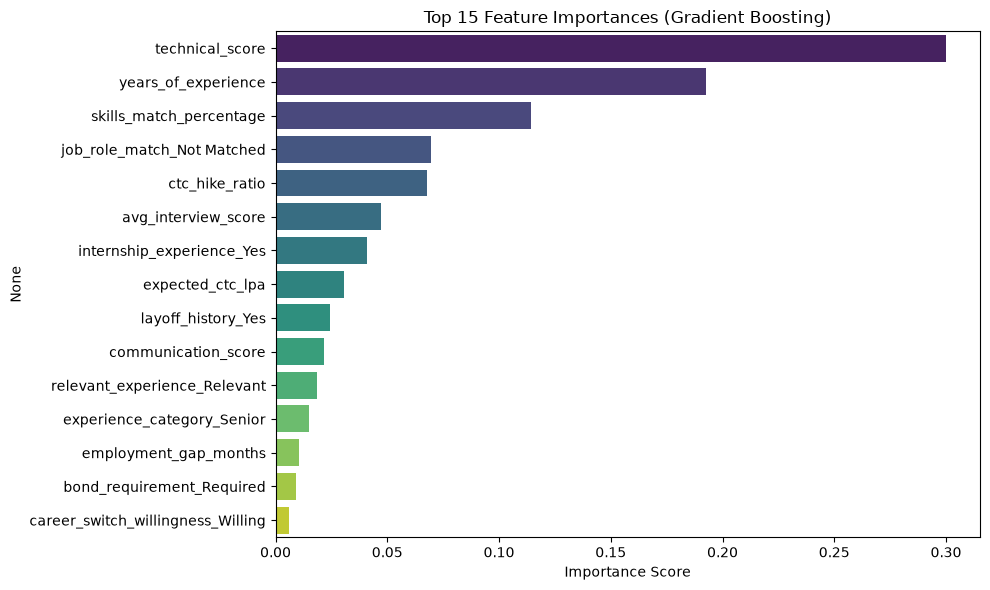


Saved best model pipeline to 'best_job_acceptance_model.pkl'!


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report
)

# 1. Load feature-engineered dataset directly from CSV
df = pd.read_csv('02_featured_hr_data.csv')

# 2. Separate Features (X) and Target (y)
drop_cols = ['status', 'target_accepted', 'high_risk_flag']
X = df.drop(columns=drop_cols)
y = df['target_accepted']

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 4. Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first'), cat_cols)
    ]
)

# 5. Define and Train Classification Models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=150, max_depth=12, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42)
}

results = []
trained_pipelines = {}

for name, clf in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('classifier', clf)])
    pipe.fit(X_train, y_train)
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1 Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })
    trained_pipelines[name] = pipe

# 6. Compare Model Performance
results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
print("=== MODEL COMPARISON TABLE ===")
display(results_df.round(4))

# 7. Detailed Report & Feature Importance for Best Model
best_model_name = results_df.loc[0, 'Model']
best_pipe = trained_pipelines[best_model_name]
print(f"\n=== BEST MODEL: {best_model_name} ===")
print(classification_report(y_test, best_pipe.predict(X_test)))

if hasattr(best_pipe.named_steps['classifier'], 'feature_importances_'):
    ohe_features = best_pipe.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(cat_cols)
    all_feature_names = num_cols + list(ohe_features)
    importances = best_pipe.named_steps['classifier'].feature_importances_
    
    feat_imp = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(15)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=feat_imp.values, y=feat_imp.index, hue=feat_imp.index, palette='viridis', legend=False)
    plt.title(f'Top 15 Feature Importances ({best_model_name})')
    plt.xlabel('Importance Score')
    plt.tight_layout()
    plt.show()

# 8. Save Best Model Pipeline for Streamlit
joblib.dump(best_pipe, 'best_job_acceptance_model.pkl')
print("\nSaved best model pipeline to 'best_job_acceptance_model.pkl'!")
